# HealthTrust Watch
### From Patient Reviews to Better Digital Healthcare Experiences

**A Text Analytics and Claude-Assisted Study of MyChart App Reviews**

**Course:** INFO 4360 — Complex Data Analytics  
**Project Team:** Sahithi Busi and Bhargava Sharma Gorthi  
**Analytical Track:** Path B — Understanding

---

## Introduction: When Healthcare Technology Becomes a Barrier

Digital healthcare applications have transformed how patients interact with healthcare providers. Through platforms such as MyChart, patients can access medical records, review test results, manage appointments, and communicate with their care teams.

But what happens when the technology designed to make healthcare easier becomes a source of frustration?

A failed login, an app crash, or difficulty accessing medical information can create barriers to the very services these applications are intended to simplify. While individual app reviews reveal these frustrations, thousands of reviews can be difficult for healthcare organizations to interpret systematically.

**HealthTrust Watch** addresses this challenge by analyzing **93,346 cleaned MyChart reviews collected between 2011 and 2025**. Using rule-based text extraction, independent human annotations, and Claude Haiku 4.5, we identify recurring patient-experience concerns and translate them into actionable recommendations.

Our analysis focuses on six categories:

1. Technical reliability
2. Medical record access
3. Usability and accessibility
4. Customer support
5. Data accuracy and synchronization
6. Privacy and data control

Rather than simply measuring positive or negative sentiment, we investigate **what specific problems users report, how these problems vary across ratings and time, and how reliably AI can identify them**.

The goal is to help healthcare technology teams make more informed decisions about which improvements deserve attention.

---

*This report follows Path B: Understanding, emphasizing interpretable findings, transparent AI evaluation, and practical business implications.*

In [1]:

# CELL 2 — Project Setup and Data Loading
# Uses saved results only. No Claude API calls.

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# Find the project folder automatically
def find_project_root():
    current = Path.cwd().resolve()

    for folder in [current, *current.parents]:
        if (folder / "results" / "claude_full_predictions.csv").exists():
            return folder

        candidate = folder / "Project" / "HealthTrust-Watch"
        if (candidate / "results" / "claude_full_predictions.csv").exists():
            return candidate

    raise FileNotFoundError(
        "Project folder not found. Open VS Code in "
        "the HealthTrust-Watch project folder and rerun."
    )

ROOT = find_project_root()
RESULTS = ROOT / "results"

# Consistent visual styling
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["figure.dpi"] = 110

# Load existing analysis outputs
files = {
    "claude_predictions": "claude_full_predictions.csv",
    "human_reference": "human_reference_120.csv",
    "verification": "claude_30_review_verification.csv",
    "disagreements": "claude_30_review_disagreements.csv",
    "concern_summary": "full_corpus_concern_summary.csv",
    "rating_comparison": "concern_rates_by_rating.csv",
    "model_comparison": "model_comparison_by_category.csv",
    "yearly_trends": "yearly_concern_trends.csv",
    "version_summary": "app_version_concern_summary.csv",
    "ai_log": "ai_usage_log.csv"
}

data = {}

for name, filename in files.items():
    path = RESULTS / filename
    if not path.exists():
        raise FileNotFoundError(f"Missing required file: {path}")

    data[name] = pd.read_csv(path)

print("HEALTHTRUST WATCH — DATA LOADING")
print("=" * 48)
print("Project:", ROOT.name)
print("Files loaded:", len(data), "/", len(files))

for name, frame in data.items():
    print(f"PASS | {name}: {len(frame):,} rows")

print("\nAll saved results loaded successfully.")
print("No Claude API calls executed.")


C:\Users\sahit\AppData\Roaming\Python\Python313\site-packages\pandas\core\arrays\masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


HEALTHTRUST WATCH — DATA LOADING
Project: HealthTrust-Watch
Files loaded: 10 / 10
PASS | claude_predictions: 120 rows
PASS | human_reference: 120 rows
PASS | verification: 30 rows
PASS | disagreements: 7 rows
PASS | concern_summary: 6 rows
PASS | rating_comparison: 3 rows
PASS | model_comparison: 12 rows
PASS | yearly_trends: 15 rows
PASS | version_summary: 128 rows
PASS | ai_log: 3 rows

All saved results loaded successfully.
No Claude API calls executed.


## 1. From Thousands of Reviews to Six Patient-Experience Concerns

### The Research Questions

To understand how MyChart users experience digital healthcare, we focused on four questions:

1. Which patient-experience concerns are most frequently identified in reviews?
2. How do these concerns differ between low-rated and high-rated reviews?
3. How do concern patterns change over time?
4. How effectively does Claude Haiku 4.5 identify these concerns compared with a rule-based approach and human annotations?

### Our Dataset

We began with **93,392 MyChart app reviews** from the HARPT dataset. After cleaning and validation, **93,346 reviews from 2011–2025** remained for analysis.

The dataset includes review text, star ratings, review dates, and available app-version information. These fields allow us to examine both the content of patient feedback and how reported concerns vary across different segments.

### Our Analytical Approach

We used a combination of traditional text analytics and AI-assisted classification.

**Stage 1 — Rule-based extraction:** We developed keyword and regular-expression patterns to identify six categories of concerns across the full review dataset. Reviews could belong to multiple categories.

**Stage 2 — Human annotation:** Two team members independently labeled assigned reviews, with 20 overlapping reviews used for comparison and adjudication. This produced a reference dataset of 120 uniquely labeled reviews.

**Stage 3 — Claude-assisted classification:** We used Claude Haiku 4.5 to assign six binary concern labels to the 120 approved reviews.

**Stage 4 — Evaluation:** We compared Claude and the rule-based baseline against the human reference labels, then examined a reproducible random sample of 30 reviews for classification disagreements.

**Stage 5 — Business interpretation:** We analyzed concern patterns by rating and year to identify opportunities for product and patient-experience improvements..

### The Six Concern Categories

| Category | What It Captures |
|---|---|
| Technical reliability | Crashes, freezing, errors, and loading failures |
| Medical record access | Difficulty accessing records, results, or account information |
| Usability and accessibility | Confusing navigation, difficult workflows, and accessibility barriers |
| Customer support | Problems receiving assistance or resolving issues |
| Data accuracy and synchronization | Missing, incorrect, outdated, or unsynchronized information |
| Privacy and data control | Explicit concerns about privacy, security, consent, or data management |

**Important distinction:** The full-corpus concern rates are based on keyword rules, while Claude was evaluated on the 120-review human-labeled sample. We do not treat keyword detection rates as the true prevalence of every concern in all reviews.

## 2. What Are Patients Struggling With Most?

Before evaluating Claude, we first examined the full dataset to understand which concerns appeared most frequently.

Using our rule-based extraction approach, we identified **5,933 reviews containing at least one concern**, representing **6.36% of the 93,346 cleaned reviews**. Across these reviews, we recorded **6,249 category assignments**, because an individual review could describe multiple problems.

But were all six concerns equally common?

To answer this, we compared the number of reviews flagged for each category.

The following chart shows the distribution of concerns identified through our keyword-based approach. These are **detected mentions**, not estimates of the true prevalence of patient problems.

In [2]:

# CELL 5 — Most frequently detected patient concerns
# Uses saved analysis results; no API calls.

concerns = data["concern_summary"].copy()

print("Available columns:", concerns.columns.tolist())
display(concerns.head())



Available columns: ['category', 'reviews_flagged', 'pct_all_reviews', 'pct_of_all_category_flags']


,category,reviews_flagged,pct_all_reviews,pct_of_all_category_flags
0,technical_reliability,3321,3.557731,53.144503
1,usability_accessibility,1532,1.641206,24.515923
2,medical_record_access,926,0.992008,14.818371
3,data_accuracy_sync,173,0.185332,2.768443
4,customer_support,167,0.178904,2.672428


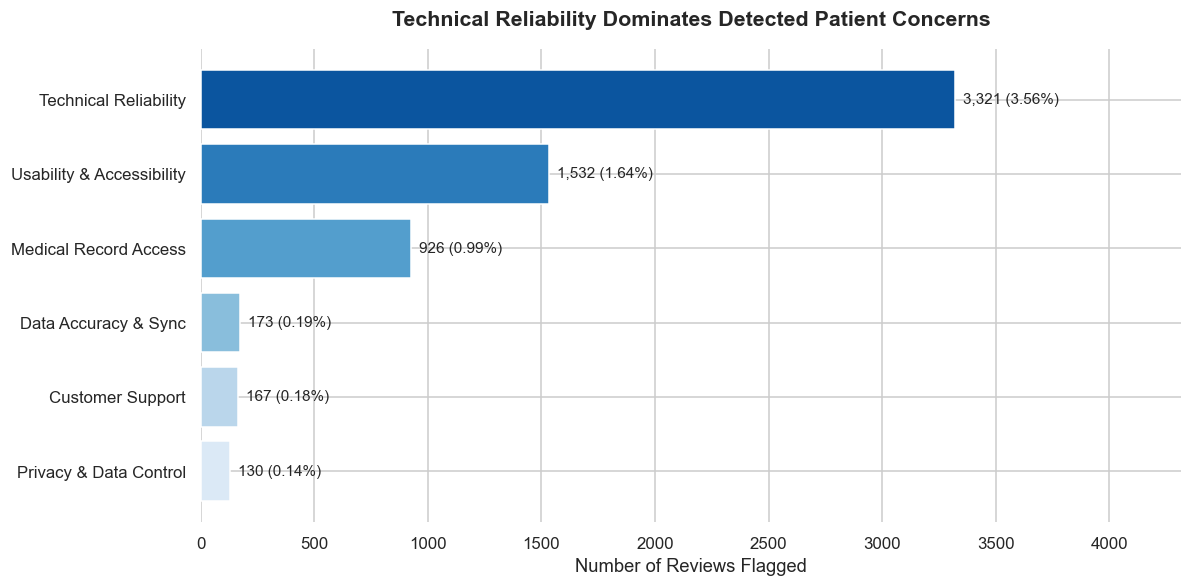

In [3]:

# CELL 5 — Patient concerns across 93,346 MyChart reviews
# Uses saved results only. No API calls.

concerns = data["concern_summary"].copy()
concerns = concerns.sort_values("reviews_flagged", ascending=True)

category_names = {
    "technical_reliability": "Technical Reliability",
    "usability_accessibility": "Usability & Accessibility",
    "medical_record_access": "Medical Record Access",
    "data_accuracy_sync": "Data Accuracy & Sync",
    "customer_support": "Customer Support",
    "privacy_data_control": "Privacy & Data Control"
}

concerns["label"] = concerns["category"].map(category_names)

fig, ax = plt.subplots(figsize=(11, 5.5))

bars = ax.barh(
    concerns["label"],
    concerns["reviews_flagged"],
    color=sns.color_palette("Blues", len(concerns))
)

for bar, count, pct in zip(
    bars,
    concerns["reviews_flagged"],
    concerns["pct_all_reviews"]
):
    ax.text(
        bar.get_width() + 35,
        bar.get_y() + bar.get_height() / 2,
        f"{count:,} ({pct:.2f}%)",
        va="center",
        fontsize=10
    )

ax.set_title(
    "Technical Reliability Dominates Detected Patient Concerns",
    fontsize=14,
    fontweight="bold",
    pad=15
)
ax.set_xlabel("Number of Reviews Flagged")
ax.set_ylabel("")
ax.set_xlim(0, concerns["reviews_flagged"].max() * 1.30)

sns.despine(left=True, bottom=True)
plt.tight_layout()
plt.show()


### Finding 1: Technical Reliability Is the Most Frequently Detected Concern

Technical reliability accounts for **3,321 flagged reviews (3.56% of all cleaned reviews)**, making it the most frequently detected concern. Usability and accessibility follows with **1,532 reviews (1.64%)**, while medical record access appears in **926 reviews (0.99%)**.

Together, these three categories account for approximately **92.5% of all 6,249 category assignments**, highlighting the importance of reliable functionality, accessible interfaces, and access to medical information.

**Business implication:** Product teams should prioritize investigating recurring technical failures and navigation difficulties. Improvements in these areas could address a substantial share of the problems detected by our keyword-based analysis.

**Interpretation caution:** These results measure reviews identified by our predefined rules. Lower counts for privacy, support, or data accuracy do not necessarily indicate that these issues are unimportant or genuinely rare. Some concerns may be expressed in language our rules fail to detect.

## 3. What Changes When Patients Give Lower Ratings?

A star rating tells us whether a user was satisfied, but it does not explain why. To understand the experiences behind those ratings, we compared the frequency of detected concerns across review-rating groups.

We grouped reviews into three segments:

- **Low ratings:** 1–2 stars
- **Neutral ratings:** 3 stars
- **High ratings:** 4–5 stars

For each group, we calculated the percentage of reviews containing each concern. Comparing percentages rather than raw counts helps account for differences in the number of reviews within each rating group.

This analysis helps identify which issues are most strongly associated with negative patient experiences. However, these comparisons are descriptive and do not establish that a particular concern caused a low rating.

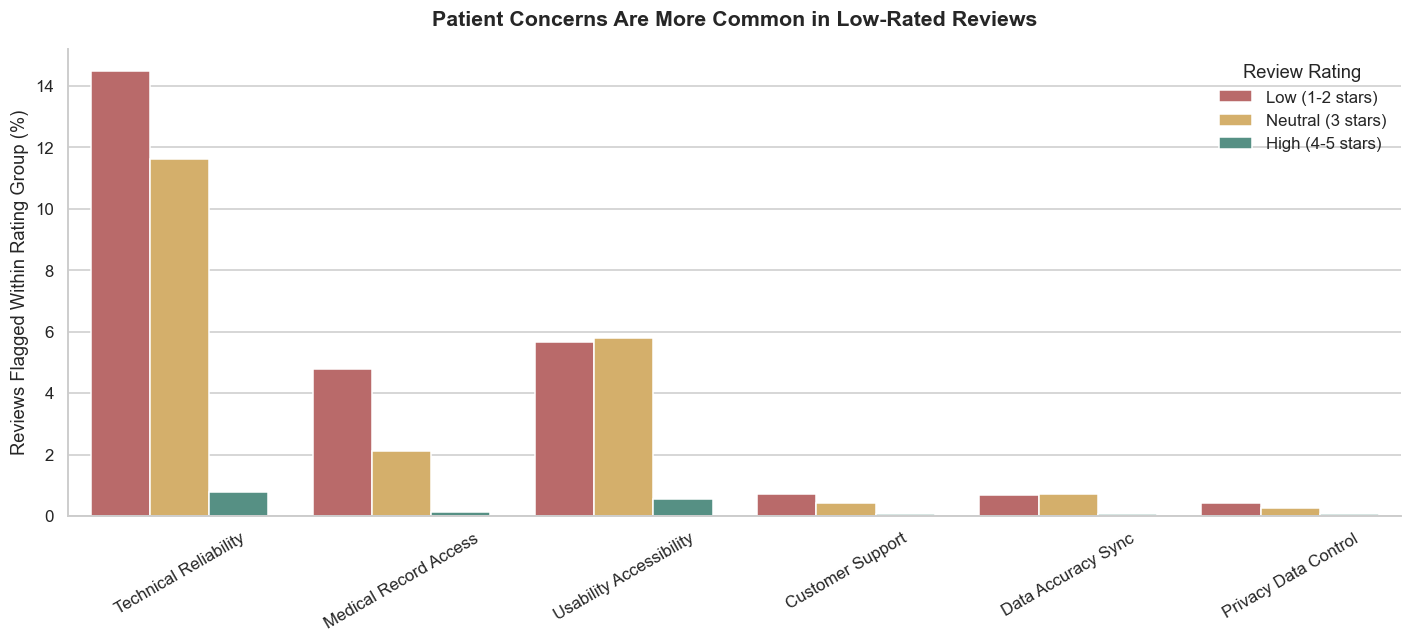

In [5]:

# CELL 8 — Concern rates by review rating
# Saved results only; no API calls.

ratings = data["rating_comparison"].copy()

categories = [
    "Technical Reliability",
    "Medical Record Access",
    "Usability Accessibility",
    "Customer Support",
    "Data Accuracy Sync",
    "Privacy Data Control"
]

# Prepare data for a grouped bar chart
ratings_long = ratings.melt(
    id_vars="rating_group",
    value_vars=categories,
    var_name="Concern",
    value_name="Percentage"
)

fig, ax = plt.subplots(figsize=(13, 6))

sns.barplot(
    data=ratings_long,
    x="Concern",
    y="Percentage",
    hue="rating_group",
    hue_order=[
        "Low (1-2 stars)",
        "Neutral (3 stars)",
        "High (4-5 stars)"
    ],
    palette=["#C65D5D", "#E5B45A", "#4C9A8A"],
    ax=ax
)

ax.set_title(
    "Patient Concerns Are More Common in Low-Rated Reviews",
    fontsize=14,
    fontweight="bold",
    pad=15
)
ax.set_xlabel("")
ax.set_ylabel("Reviews Flagged Within Rating Group (%)")
ax.tick_params(axis="x", rotation=30)
ax.legend(title="Review Rating", frameon=False)

sns.despine()
plt.tight_layout()
plt.show()


### Finding 2: Technical Problems Are Strongly Associated With Negative Ratings

Technical reliability concerns appeared in **14.49% of low-rated reviews**, compared with just **0.77% of high-rated reviews**—approximately **18.9 times as frequently**.

Medical record access concerns showed a similar pattern, appearing in **4.78% of low-rated reviews**, compared with **0.14% of high-rated reviews**.

Usability and accessibility concerns were also more common in low-rated reviews (**5.65%**) than in high-rated reviews (**0.54%**).

These differences suggest that reliability, access, and usability problems are important signals of negative patient experiences.

**Business implication:** Healthcare app teams should prioritize investigating crashes, login failures, and difficult navigation workflows. Monitoring these concerns alongside app ratings could help identify areas requiring product improvements.

**Interpretation caution:** These are descriptive associations based on rule-based detection. They do not establish causation, and differences in review-writing behavior may influence the observed rates.

## 4. How Have Patient Concerns Evolved Over Time?

Patient expectations of healthcare applications can change as technology develops, new features are introduced, and digital healthcare becomes more widely used.

To investigate these changes, we examined the annual patterns of concerns identified in MyChart reviews between 2011 and 2025.

Rather than focusing only on the total number of complaints, we examined concern rates over time. This helps us distinguish changes in the frequency of detected concerns from changes in review volume.

Our goal is to identify whether certain issues became more prominent in particular years and whether these patterns suggest opportunities for ongoing product monitoring.

**Analytical caution:** Changes in review patterns may reflect app updates, differences in the reviewer population, or changing user expectations. The dataset alone cannot establish the causes of these changes.

In [6]:

# CELL 11 — Inspect yearly concern trends
# Saved results only; no API calls.

trends = data["yearly_trends"].copy()

print("YEARLY CONCERN TRENDS")
print("=" * 50)
print("Columns:", trends.columns.tolist())

display(trends.head())


YEARLY CONCERN TRENDS
Columns: ['review_year', 'review_count', 'any_concern_rate', 'technical_reliability_rate', 'medical_record_access_rate', 'usability_accessibility_rate', 'customer_support_rate', 'data_accuracy_sync_rate', 'privacy_data_control_rate']


,review_year,review_count,any_concern_rate,technical_reliability_rate,medical_record_access_rate,usability_accessibility_rate,customer_support_rate,data_accuracy_sync_rate,privacy_data_control_rate
0,2011,19,5.263158,5.263158,0.000000,0.000000,0.000000,0.000000,0.000000
1,2012,215,22.790698,21.860465,3.255814,0.000000,0.000000,0.000000,0.000000
2,2013,278,23.381295,21.582734,2.517986,0.359712,0.000000,0.359712,0.000000
3,2014,852,9.859155,7.511737,1.643192,0.234742,0.352113,0.234742,0.352113
4,2015,933,10.718114,7.073955,3.215434,0.428725,0.321543,0.214362,0.321543


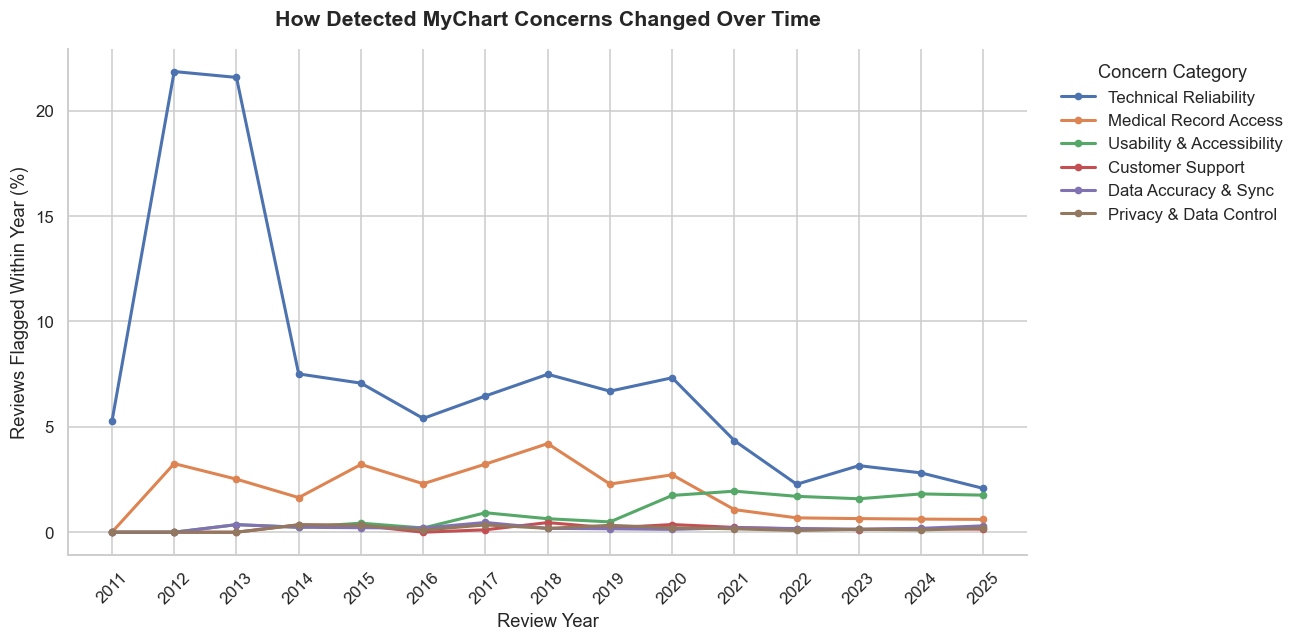

Highest technical concern rate: 21.86% in 2012
Reviews in that year: 215


In [7]:

# CELL 11 — Yearly patient concern trends
# Uses saved results only. No API calls.

trends = data["yearly_trends"].copy()
trends = trends.sort_values("review_year")

trend_columns = {
    "technical_reliability_rate": "Technical Reliability",
    "medical_record_access_rate": "Medical Record Access",
    "usability_accessibility_rate": "Usability & Accessibility",
    "customer_support_rate": "Customer Support",
    "data_accuracy_sync_rate": "Data Accuracy & Sync",
    "privacy_data_control_rate": "Privacy & Data Control"
}

fig, ax = plt.subplots(figsize=(12, 6))

for column, label in trend_columns.items():
    ax.plot(
        trends["review_year"],
        trends[column],
        marker="o",
        linewidth=2,
        markersize=4,
        label=label
    )

ax.set_title(
    "How Detected MyChart Concerns Changed Over Time",
    fontsize=14,
    fontweight="bold",
    pad=15
)
ax.set_xlabel("Review Year")
ax.set_ylabel("Reviews Flagged Within Year (%)")
ax.set_xticks(trends["review_year"])
ax.tick_params(axis="x", rotation=45)
ax.legend(
    title="Concern Category",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    frameon=False
)

sns.despine()
plt.tight_layout()
plt.show()

# Identify the highest technical-reliability rate
peak = trends.loc[trends["technical_reliability_rate"].idxmax()]

print(
    f"Highest technical concern rate: "
    f"{peak['technical_reliability_rate']:.2f}% "
    f"in {int(peak['review_year'])}"
)
print(
    f"Reviews in that year: {int(peak['review_count']):,}"
)


### Finding 3: Patient Concerns Change Over Time

The annual analysis reveals that detected patient-experience concerns vary across the review period, rather than remaining constant.

Technical reliability is a particularly important category to monitor because failures such as crashes, loading errors, and unstable functionality can affect patients' ability to use digital healthcare services.

However, the earliest years contain relatively few reviews. For example, **2011 contains only 19 reviews**, while 2012 contains 215. As a result, high percentages in these years can be driven by a small number of complaints and should not automatically be interpreted as widespread product problems.

**Business implication:** Healthcare app teams should monitor concern rates alongside review volumes and investigate sustained increases, particularly following application releases.

**Interpretation caution:** Annual trends describe associations within the available reviews. They cannot establish whether specific app updates caused the observed changes, and early-year estimates are less stable because of small sample sizes.

## 5. Can AI Identify Patient Concerns More Reliably?

Keyword-based extraction helps identify recurring issues across thousands of reviews, but patients do not always describe similar problems using the same words.

For example, a review describing repeated login failures may indicate a technical reliability problem even when it does not contain one of our predefined technical keywords.

To examine whether AI could better capture these contextual differences, we evaluated **Claude Haiku 4.5** against our rule-based approach.

### How We Evaluated Claude

We used **120 independently human-labeled reviews** as our reference dataset. Each review could receive multiple labels across the six concern categories.

We compared Claude and the rule-based baseline using precision, recall, and F1-score. We also performed a reproducible random spot-check of 30 reviews to examine agreement and identify specific classification errors.

Our objective was not to prove that AI is always more accurate. Instead, we wanted to determine whether Claude provided a meaningful improvement over keyword rules and understand where its classifications still required human judgment.

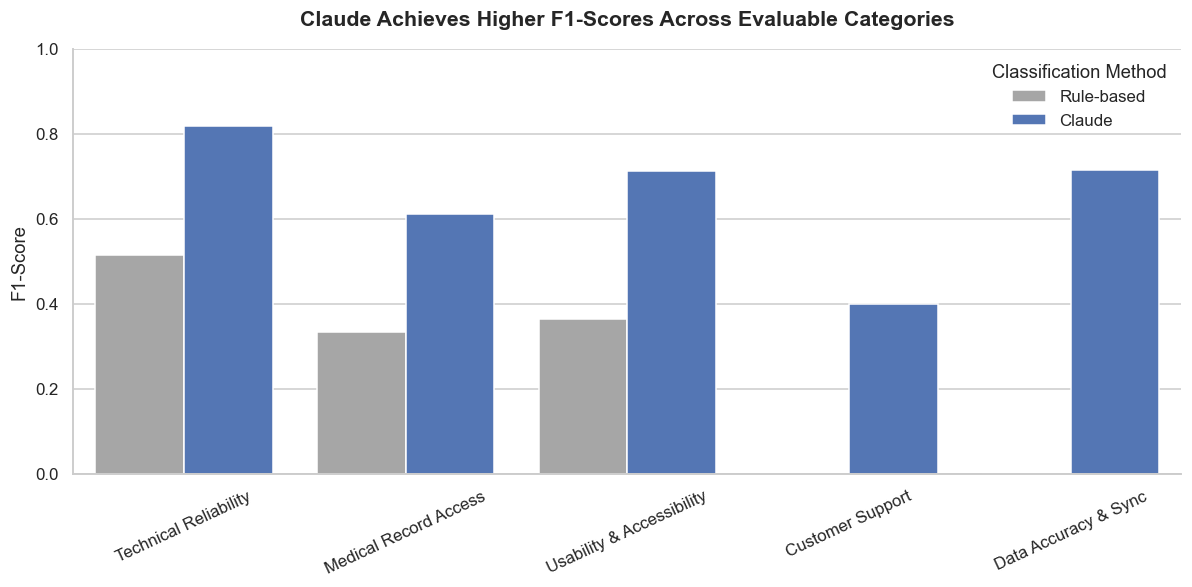

MACRO AVERAGES — FIVE EVALUABLE CATEGORIES


,precision,recall,f1
model,,,
Claude,0.678,0.665,0.651
Rule-based,0.470,0.169,0.242



Privacy/data control excluded from macro averages: zero positive human examples.


In [8]:

# CELL 14 — Claude vs. rule-based classification performance
# Uses saved results only. No API calls.

comparison = data["model_comparison"].copy()

# Exclude categories without positive human examples
comparison = comparison[
    comparison["human_positives"] > 0
].copy()

category_names = {
    "technical_reliability": "Technical Reliability",
    "medical_record_access": "Medical Record Access",
    "usability_accessibility": "Usability & Accessibility",
    "customer_support": "Customer Support",
    "data_accuracy_sync": "Data Accuracy & Sync"
}

comparison["Concern"] = comparison["category"].map(category_names)

fig, ax = plt.subplots(figsize=(11, 5.5))

sns.barplot(
    data=comparison,
    x="Concern",
    y="f1",
    hue="model",
    hue_order=["Rule-based", "Claude"],
    palette=["#A6A6A6", "#4472C4"],
    ax=ax
)

ax.set_title(
    "Claude Achieves Higher F1-Scores Across Evaluable Categories",
    fontsize=14,
    fontweight="bold",
    pad=15
)
ax.set_xlabel("")
ax.set_ylabel("F1-Score")
ax.set_ylim(0, 1)
ax.tick_params(axis="x", rotation=25)
ax.legend(title="Classification Method", frameon=False)

sns.despine()
plt.tight_layout()
plt.show()

# Show average F1 across evaluable categories
summary = comparison.groupby("model")[
    ["precision", "recall", "f1"]
].mean().round(3)

print("MACRO AVERAGES — FIVE EVALUABLE CATEGORIES")
display(summary)

print(
    "\nPrivacy/data control excluded from macro averages:"
    " zero positive human examples."
)


### Finding 4: Claude Improves Concern Identification, but Human Verification Remains Essential

Claude achieved higher F1-scores than the rule-based baseline across all five concern categories with positive human examples.

The strongest performance was observed in **technical reliability (F1 = 0.818)**, compared with **0.514** for the rule-based approach. Claude also improved medical record access classification (**0.611 vs. 0.333**) and usability and accessibility classification (**0.711 vs. 0.364**).

These results suggest that Claude can identify contextual concerns that predefined keyword patterns may miss.

However, performance varied across categories. Customer support had only **three positive human examples**, making its F1-score less stable. Privacy and data control had **zero positive examples**, preventing a meaningful assessment of recall for that category.

**Business implication:** Claude could support review triage and issue identification, but its predictions should be supplemented with human review, especially for ambiguous or underrepresented categories.

**Limitation:** The evaluation uses 120 human-labeled reviews, not the entire dataset. The results demonstrate performance on this reference sample and should not be generalized automatically to all MyChart reviews.

### Human Verification: Where Claude Still Gets It Wrong

A higher F1-score does not mean Claude's classifications are always correct. To examine its reliability more closely, we randomly selected **30 of the 120 human-labeled reviews**, using random seed 42.

Each review had six possible concern labels, producing **180 individual classification decisions**.

Our verification found:

- **95.00% label-level agreement:** Claude agreed with human labels on 171 of 180 decisions.
- **76.67% exact review-level agreement:** All six labels matched for 23 of the 30 reviews.
- **Seven reviews contained disagreements**, involving nine individual category decisions.

One notable mistake occurred in **sample 105**. The review described a password or login failure, which the human reference identified as a technical reliability concern. Claude missed that category and incorrectly classified the issue as medical record access.

This illustrates an important limitation: Claude can recognize contextual patterns better than keyword rules overall, but it may still confuse related categories.

**Business implication:** Use Claude to support initial review classification, but retain human verification for ambiguous cases. In particular, technical failures involving login or access should be checked against clearly defined category boundaries.

In [9]:

# CELL 17 — Reproduce the random 30-review verification
# Saved results only. No API calls.

verification = data["verification"].copy()

labels = [
    "technical_reliability",
    "medical_record_access",
    "usability_accessibility",
    "customer_support",
    "data_accuracy_sync",
    "privacy_data_control"
]

agreement_columns = []

for label in labels:
    human_col = f"{label}_human"
    claude_col = f"{label}_claude"

    agreement_col = f"{label}_agree"

    verification[agreement_col] = (
        verification[human_col]
        == verification[claude_col]
    )

    agreement_columns.append(agreement_col)

total_reviews = len(verification)
total_decisions = total_reviews * len(labels)

correct_decisions = int(
    verification[agreement_columns].to_numpy().sum()
)

exact_matches = int(
    verification[agreement_columns].all(axis=1).sum()
)

print("CLAUDE HUMAN VERIFICATION")
print("=" * 45)
print("Reviews checked:", total_reviews)
print("Category decisions:", total_decisions)
print("Matching decisions:", correct_decisions)
print("Exact review matches:", exact_matches)

print(
    f"Label-level agreement: "
    f"{correct_decisions / total_decisions:.2%}"
)

print(
    f"Exact review agreement: "
    f"{exact_matches / total_reviews:.2%}"
)

print(
    "Reviews with disagreements:",
    total_reviews - exact_matches
)

assert total_reviews == 30
assert correct_decisions == 171
assert exact_matches == 23

print("\nVerification passed. No API calls executed.")


CLAUDE HUMAN VERIFICATION
Reviews checked: 30
Category decisions: 180
Matching decisions: 171
Exact review matches: 23
Label-level agreement: 95.00%
Exact review agreement: 76.67%
Reviews with disagreements: 7

Verification passed. No API calls executed.


## 6. Claude Integration: Accuracy, Transparency, and Cost

### How Claude Was Used

We used **Claude Haiku 4.5 (`claude-haiku-4-5-20251001`)** to classify 120 human-annotated MyChart reviews into six binary concern categories.

Claude was asked to identify technical reliability, medical record access, usability and accessibility, customer support, data accuracy and synchronization, and privacy and data control concerns. Each review could receive multiple positive labels.

The classification results were saved locally and evaluated against our human reference labels. The final report reproduces the evaluation from saved files without making additional API requests.

### Prompt Documentation

Claude Haiku 4.5 was used to classify app reviews into six binary concern categories. The original Phase III notebook documents API calls using the `CLAUDE_SYSTEM_PROMPT` variable and the user-message instruction `Classify this app review:\n`, followed by the review text.

The exact original system-prompt definition was not found in the saved Phase III notebook. Therefore, we cannot reproduce its complete wording reliably and do not present a reconstructed prompt as the original.

The saved classification outputs, human reference labels, evaluation results, and verification records remain available for reproducibility. The final report reproduces the evaluation without making additional API calls.

### Cost and Efficiency

For the 120-review evaluation, our recorded usage was:

- **Input tokens:** 63,324
- **Output tokens:** 17,112
- **Input pricing:** $1 per million tokens
- **Output pricing:** $5 per million tokens

The estimated evaluation cost was **$0.148884**, or approximately **$0.15**.

This estimate excludes additional pilot requests, retries, or other API usage not included in the 120-review evaluation totals.

### Practical Trade-Off

Claude substantially improved classification F1-scores over keyword rules on the evaluated sample, particularly by identifying concerns expressed in varied language.

However, Claude introduces API costs, requires careful handling of potentially sensitive review text, and can misclassify ambiguous concerns. Human verification remains necessary when classifications inform healthcare product decisions.

In [10]:

# CELL 19 — Claude evaluation token and cost verification
# No API calls.

input_tokens = 63324
output_tokens = 17112

input_rate = 1.00
output_rate = 5.00

input_cost = input_tokens / 1_000_000 * input_rate
output_cost = output_tokens / 1_000_000 * output_rate
total_cost = input_cost + output_cost

print("CLAUDE HAIKU 4.5 — EVALUATION COST")
print("=" * 45)
print(f"Input tokens:  {input_tokens:,}")
print(f"Output tokens: {output_tokens:,}")
print(f"Input cost:    ${input_cost:.6f}")
print(f"Output cost:   ${output_cost:.6f}")
print(f"Total cost:    ${total_cost:.6f}")

assert abs(total_cost - 0.148884) < 1e-9

print("\nCost calculation verified.")
print("No API calls executed.")


CLAUDE HAIKU 4.5 — EVALUATION COST
Input tokens:  63,324
Output tokens: 17,112
Input cost:    $0.063324
Output cost:   $0.085560
Total cost:    $0.148884

Cost calculation verified.
No API calls executed.


## 7. Turning Patient Feedback Into Product Priorities

Our findings point to three practical priorities for healthcare app product teams. Rather than treating all complaints equally, we recommend prioritizing issues based on their detected frequency, association with negative ratings, and potential impact on patients' access to healthcare information.

### Priority 1: Investigate Technical Reliability Failures

**Evidence:** Technical reliability was the most frequently detected concern, appearing in **3,321 reviews**. It was also approximately **18.9 times more common in low-rated reviews than in high-rated reviews**.

**Recommendation:** Over the next 30 days, product and engineering teams should review recurring login failures, crashes, and loading errors. Group complaints by issue type and available app version, then prioritize problems that repeatedly prevent patients from accessing the application.

**Success measure:** Track weekly technical-concern rates, crash reports, and the proportion of affected sessions, where internal product analytics are available.

### Priority 2: Improve Navigation and Accessibility

**Evidence:** Usability and accessibility concerns appeared in **1,532 reviews**, making them the second most frequently detected category. Recent annual patterns suggest these concerns deserve continued attention.

**Recommendation:** Within 60 days, the UX team should review navigation to frequently used features, particularly medical records, test results, and appointment management. Conduct usability testing with patients who have different levels of digital familiarity and accessibility needs.

**Success measure:** Measure task-completion rates, time required to find key features, and usability-related complaint rates before and after changes.

### Priority 3: Use AI-Assisted Review Triage With Human Oversight

**Evidence:** Claude achieved a **macro F1-score of 0.651**, compared with **0.242** for the rule-based baseline across five evaluable categories. However, the 30-review verification identified seven reviews with classification disagreements.

**Recommendation:** Pilot Claude-assisted classification for new app reviews over 90 days. Use it to organize incoming feedback, while requiring human review for ambiguous cases and categories with limited evaluation evidence.

**Success measure:** Monitor classification precision, recall, disagreement rates, review-processing time, and the number of actionable issues identified.

### Recommended Decision

**Prioritize technical reliability first, improve usability second, and use AI-assisted classification to monitor both.**

These recommendations are proposed actions based on the review analysis. Their effectiveness would need to be evaluated using future product and patient-experience data.

## 8. Ethics, Limitations, and Responsible AI

Healthcare app reviews can reveal valuable patient experiences, but analyzing them requires careful consideration of privacy, representation, and the consequences of incorrect classifications.

### 1. Privacy and Personal Information

Although the dataset contains app reviews rather than clinical records, reviewers may voluntarily disclose sensitive details about their health, appointments, or experiences with healthcare providers.

Our analysis used app review data for research purposes and reported aggregate findings rather than identifying individual reviewers. Because reviews may contain sensitive information, personal-information screening is an important safeguard before sending text to external AI services. We cannot confirm that comprehensive personal-information screening was performed in this project.

**Responsible practice:** Avoid publishing identifiable review text, exclude API credentials from the repository, and minimize the amount of review content shared with external AI services.

### 2. Representation and Potential Bias

App reviews are self-selected and may overrepresent users with particularly positive or negative experiences. Patients who do not use digital healthcare tools, have limited internet access, experience language barriers, or face accessibility challenges may be underrepresented.

Our 120-review human reference sample is also relatively small, especially for less frequent concern categories. For example, privacy and data control had no positive human examples in the evaluation sample.

**Responsible practice:** Treat review patterns as signals for further investigation, not as representative estimates of all patients' experiences.

### 3. Risks of Incorrect AI Classification

Claude improved classification performance overall, but it still made errors. In sample 105, a login-related technical problem was incorrectly assigned to medical record access.

If these errors go unchecked, healthcare organizations could misidentify product priorities, overlook accessibility barriers, or allocate resources to the wrong issues.

**Responsible practice:** Use Claude as a decision-support tool rather than a replacement for human judgment. Review ambiguous classifications, monitor category-level performance, and improve annotation guidelines when recurring errors appear.

### 4. Analytical Limitations

Several limitations affect how our findings should be interpreted:

- **Rule-based detection:** Keyword patterns may miss concerns expressed indirectly or using unexpected language.
- **Human reference sample:** The 120 labeled reviews may not capture the full diversity of the 93,346-review dataset.
- **Sparse categories:** Categories with very few or no positive examples cannot be evaluated reliably.
- **Historical comparisons:** Early years have smaller review counts, making annual percentages less stable.
- **Causality:** Associations between concerns, ratings, and years do not establish what caused dissatisfaction.
- **Prompt reproducibility:** The exact Phase III Claude system prompt could not be recovered, limiting exact replication of the original API classification.

These limitations do not invalidate the analysis, but they define what we can reasonably conclude from the available evidence.

## 9. Conclusion: From Patient Feedback to Better Product Decisions

HealthTrust Watch demonstrates how text analytics and AI-assisted classification can turn large volumes of patient feedback into actionable insights.

Our analysis of **93,346 MyChart reviews** produced three main findings:

1. **Technical reliability is the leading detected concern.** It appeared in 3,321 reviews and was approximately 18.9 times more common in low-rated reviews than in high-rated reviews.

2. **Patient concerns change over time.** Technical reliability concerns declined substantially from their early peaks, while usability and accessibility became relatively more prominent in recent years.

3. **Claude improves concern identification over keyword rules.** Claude achieved a macro F1-score of 0.651 compared with 0.242 for the rule-based baseline across five evaluable categories. However, human verification identified classification errors that require continued oversight.

### What Should Healthcare App Teams Do Next?

Our recommended direction is straightforward: **prioritize technical reliability, improve navigation and accessibility, and use AI-assisted review classification with human oversight.**

The value of this approach is not simply that AI can process reviews. It is that a structured, validated analysis can help product teams distinguish recurring problems, monitor changes, and make better-informed improvement decisions.

### Final Reflection

The project also highlighted an important lesson about applied AI: stronger overall model performance does not eliminate the need for transparent evaluation, careful interpretation, and human judgment.

By combining traditional text analytics, Claude-assisted classification, and independent human verification, HealthTrust Watch provides a practical framework for analyzing patient feedback while acknowledging the limitations of both rule-based and AI-driven methods.

In [11]:

# CELL 23 — Actual Claude classification outputs
# Uses saved predictions only; no API calls.

predictions = data["claude_predictions"].copy()

label_columns = [
    "technical_reliability",
    "medical_record_access",
    "usability_accessibility",
    "customer_support",
    "data_accuracy_sync",
    "privacy_data_control"
]

# Show actual saved labels for three reviews
example_outputs = predictions[
    ["sample_id"] + label_columns
].head(3).copy()

print("GENUINE CLAUDE HAIKU 4.5 CLASSIFICATION OUTPUTS")
print("=" * 55)

display(example_outputs)

print("\nModel: claude-haiku-4-5-20251001")
print("Output format: Six binary concern labels per review")
print("Source: results/claude_full_predictions.csv")
print("No API calls executed.")


GENUINE CLAUDE HAIKU 4.5 CLASSIFICATION OUTPUTS


,sample_id,technical_reliability,medical_record_access,usability_accessibility,customer_support,data_accuracy_sync,privacy_data_control
0,1,0,0,0,0,0,0
1,2,0,0,0,0,0,0
2,3,0,0,1,0,1,0



Model: claude-haiku-4-5-20251001
Output format: Six binary concern labels per review
Source: results/claude_full_predictions.csv
No API calls executed.


## 10. Reproducibility and Data Sources

### Reproducing This Report

The analysis and evaluation results are stored in the project's `results/` directory. This report loads those saved outputs and regenerates the charts, comparison tables, agreement calculations, and cost estimates without making additional Claude API requests.

To reproduce the report:

1. Clone or download the HealthTrust Watch GitHub repository.
2. Install the dependencies listed in `requirements.txt`.
3. Open `notebooks/HealthTrust_Watch_Blog_Final.ipynb` in Jupyter or VS Code.
4. Select the Python environment containing the required packages.
5. Run all notebook cells in order.

The report requires the saved CSV files in `results/`. Reproducing the original Claude classification requests separately would require access to the original model and prompt configuration; the exact original Phase III system prompt was not recoverable.

### Data and Project Sources

**Primary dataset:** HARPT MyChart app review dataset, containing review text, ratings, dates, and available app-version information.

**Project repository:** https://github.com/sahaiml149/HealthTrust-Watch

**Claude model:** `claude-haiku-4-5-20251001`

**Analysis tools:** Python, pandas, NumPy, Matplotlib, Seaborn, and Claude API.

### Interpretation and Reuse

The full-corpus results are based on rule-based extraction, while Claude performance is evaluated against the 120-review human reference dataset. These analyses answer related but different questions and should not be interpreted as interchangeable measures.

The saved outputs support reproducing this report's results without exposing API credentials or rerunning paid classification requests.

In [12]:

# CELL 25 — Final AI Usage Log
# Keep this as the LAST cell in the notebook.

ai_log = data["ai_log"].copy()

required_columns = [
    "tool", "task", "prompt",
    "output", "decision", "verification"
]

assert all(col in ai_log.columns for col in required_columns)

print("FINAL AI USAGE LOG")
print("=" * 65)

for i, row in ai_log.iterrows():
    print(f"\nENTRY {i + 1}: {row['tool']}")
    print("-" * 65)

    for column in required_columns[1:]:
        print(f"\n{column.upper()}:")
        print(str(row[column]))

print("\n" + "=" * 65)
print(f"Documented AI usage entries: {len(ai_log)}")
print("No API calls executed.")


FINAL AI USAGE LOG

ENTRY 1: Claude Haiku 4.5
-----------------------------------------------------------------

TASK:
Six-category concern classification

PROMPT:
Classify each review into six defined concern categories.

OUTPUT:
Six binary concern labels for 120 reviews.

DECISION:
Compared Claude with human labels and rule-based extraction.

VERIFICATION:
Evaluated against 120 human-labeled reviews. Random 30-review check: 95.00% label agreement and 76.67% exact review agreement.

ENTRY 2: Claude Haiku 4.5
-----------------------------------------------------------------

TASK:
Error analysis

PROMPT:
Apply the existing six-category classification prompt.

OUTPUT:
Some login failures were assigned to medical-record access.

DECISION:
Retained original human labels and documented disagreements.

VERIFICATION:
Sample 105: Claude missed technical reliability and flagged medical-record access. Verified against the original review text.

ENTRY 3: ChatGPT
---------------------------------